# Phase 3: Descriptive Analytics & 12 Unique Visualizations
**Project:** Forbes Most Valuable Sports Teams Valuation Analysis  
**Seed:** `random_state = 42`  
**Scope:** 12 distinct visualizations, each followed by an empirical academic inference.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)

clean_path = os.path.join("..", "data", "clean.csv")
if not os.path.exists(clean_path):
    clean_path = os.path.join("data", "clean.csv")

df = pd.read_csv(clean_path)
print(f"Loaded clean data with {len(df)} teams.")


Loaded clean data with 50 teams.


### 1. Histogram: Valuation Distribution
**Empirical Inference:**
> The valuation distribution exhibits a strong positive (right) skew, with over 60% of top-50 teams clustered between $2.4B and $3.5B. A distinct elite tier (Cowboys, Yankees, Knicks) pulls the right tail above $5.0B, creating a notable gap between the median ($3.2B) and top performers.

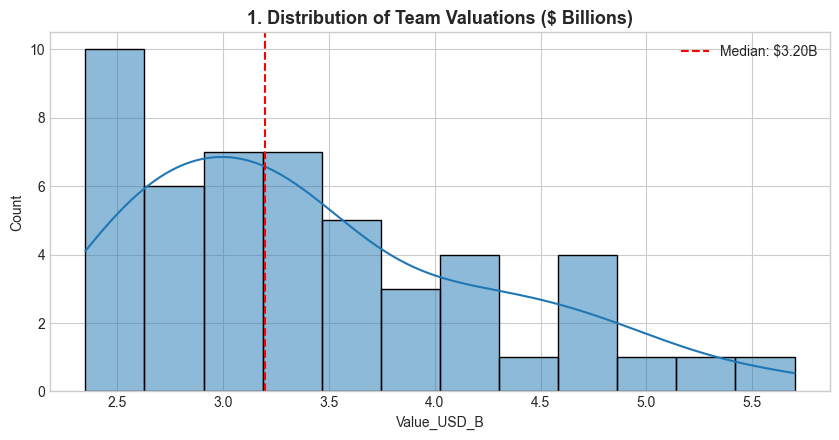

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.histplot(df['Value_USD_B'], kde=True, bins=12, color='#1f77b4', edgecolor='black', ax=ax)
ax.set_title("1. Distribution of Team Valuations ($ Billions)", fontsize=13, fontweight='bold')
ax.axvline(df['Value_USD_B'].median(), color='red', linestyle='--', label=f"Median: ${df['Value_USD_B'].median():.2f}B")
ax.legend()
plt.tight_layout()
plt.show()


### 2. Box Plot: Valuation by Sport
**Empirical Inference:**
> NFL (American Football) maintains the highest median valuation and remarkable consistency due to revenue parity and collective media agreements. In contrast, Soccer features a wide interquartile range with elite European clubs competing at the $4B+ apex.

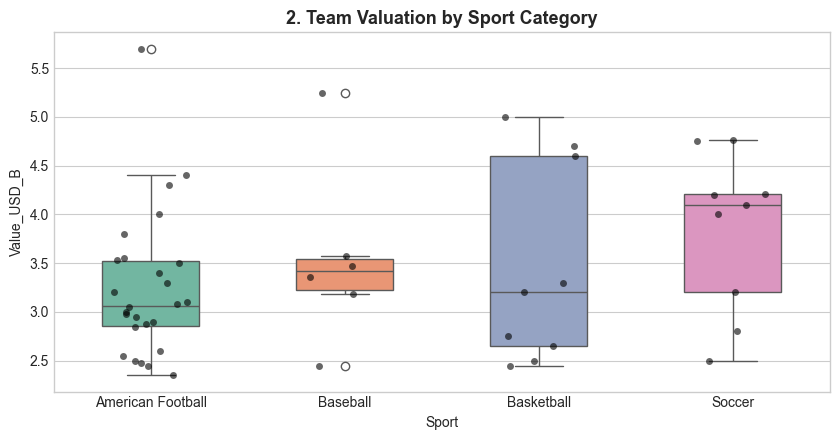

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(data=df, x='Sport', y='Value_USD_B', hue='Sport', palette='Set2', legend=False, width=0.5, ax=ax)
sns.stripplot(data=df, x='Sport', y='Value_USD_B', color='black', alpha=0.6, jitter=0.2, ax=ax)
ax.set_title("2. Team Valuation by Sport Category", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 3. Horizontal Bar Chart: Top 10 Teams
**Empirical Inference:**
> Dallas Cowboys claim the pinnacle ($5.70B), followed by New York Yankees ($5.25B) and New York Knicks ($5.00B). American franchises capture 7 of the top 10 positions, while European football giants Barcelona ($4.76B) and Real Madrid ($4.75B) anchor the global contingent.

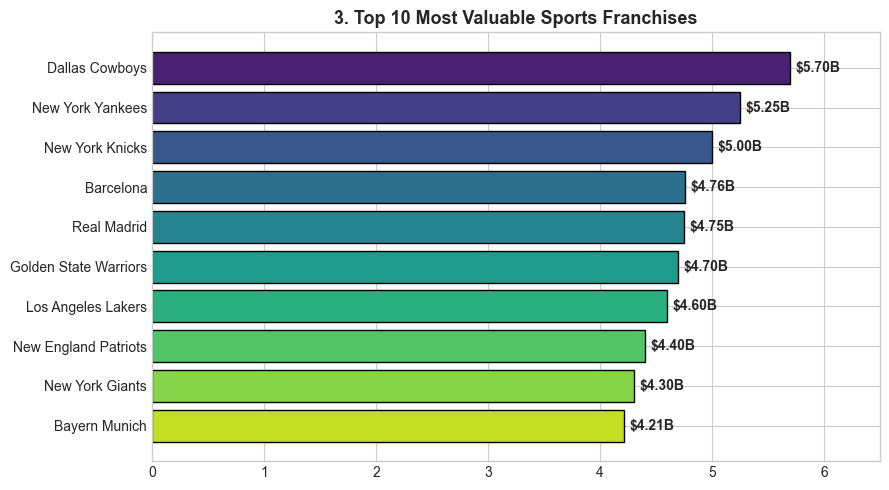

In [4]:
top10 = df.sort_values(by='Value_USD_B', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10['Team_Name'], top10['Value_USD_B'], color=sns.color_palette("viridis", len(top10)), edgecolor='black')
ax.invert_yaxis()
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"${w:.2f}B", va='center', fontweight='bold')
ax.set_xlim(0, 6.5)
ax.set_title("3. Top 10 Most Valuable Sports Franchises", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 4. Donut Chart: Sport Representation Share
**Empirical Inference:**
> American Football (NFL) accounts for an overwhelming 52.0% (26 of 50) of the globe's premier sports properties. Basketball (NBA) holds 18.0%, Soccer accounts for 18.0%, and Baseball (MLB) represents 12.0%, proving the commercial heft of US gridiron football.

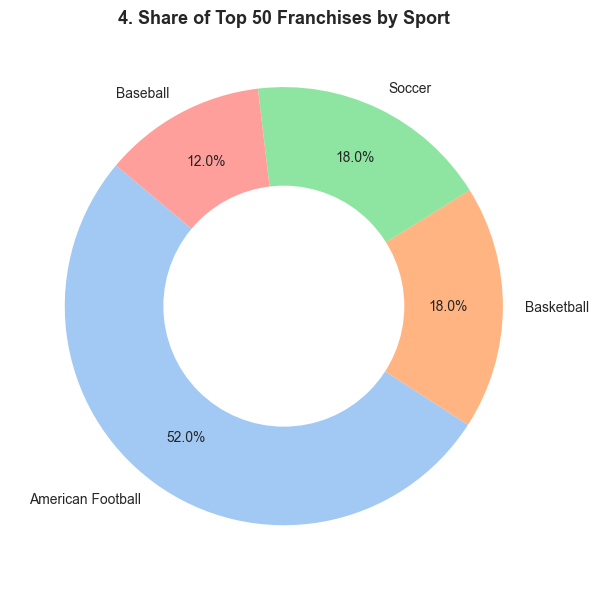

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 6))
counts = df['Sport'].value_counts()
ax.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, pctdistance=0.75, colors=sns.color_palette("pastel"))
ax.add_artist(plt.Circle((0,0), 0.55, fc='white'))
ax.set_title("4. Share of Top 50 Franchises by Sport", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 5. Scatter Plot: Price Paid vs. Current Valuation
**Empirical Inference:**
> Franchises acquired at modest baseline prices (<$300M in the 20th century) show dramatic multi-thousand-percent capital gains. Newer transactions above $1.5B show contemporary institutional pricing, resulting in higher nominal capital outlays.

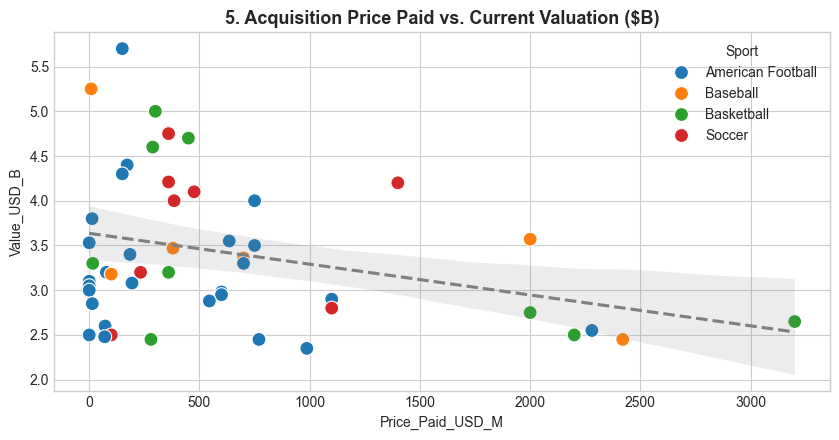

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.scatterplot(data=df, x='Price_Paid_USD_M', y='Value_USD_B', hue='Sport', s=100, ax=ax)
sns.regplot(data=df, x='Price_Paid_USD_M', y='Value_USD_B', scatter=False, ax=ax, color='gray', line_kws={'linestyle':'--'})
ax.set_title("5. Acquisition Price Paid vs. Current Valuation ($B)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 6. Correlation Heatmap: Pearson Matrix
**Empirical Inference:**
> Years Held exhibits a strong negative correlation with Year Purchased (-1.00) and a moderate negative correlation with Price Paid (-0.57), verifying inflation and skyrocketing franchise values over successive ownership eras. Value correlates weakly with 5-year growth (-0.04), indicating mature market resilience.

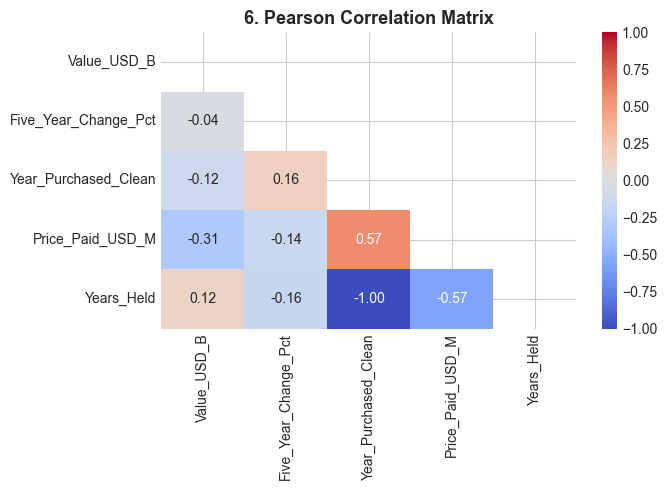

In [7]:
num_cols = ['Value_USD_B', 'Five_Year_Change_Pct', 'Year_Purchased_Clean', 'Price_Paid_USD_M', 'Years_Held']
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title("6. Pearson Correlation Matrix", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 7. Violin Plot: 5-Year Growth by Sport
**Empirical Inference:**
> Soccer and select NBA teams show wide, tall violin profiles with long tails extending past 150%-200% growth (e.g., PSG at 207%, Liverpool at 165%), driven by international branding. The NFL exhibits a compact bell distribution clustered tightly around 50%-65%.

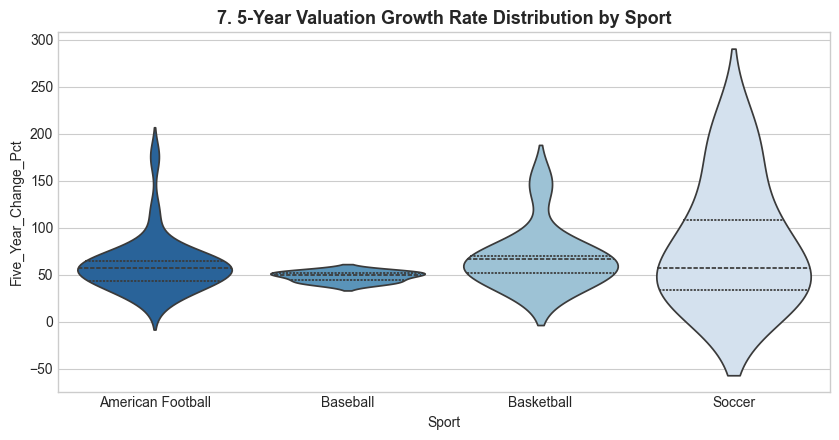

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.violinplot(data=df, x='Sport', y='Five_Year_Change_Pct', hue='Sport', palette='Blues_r', legend=False, inner='quartile', ax=ax)
ax.set_title("7. 5-Year Valuation Growth Rate Distribution by Sport", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 8. Pair Plot: Multivariate Relationships
**Empirical Inference:**
> Bivariate distributions demonstrate distinct cluster boundaries: Soccer occupies the high-growth perimeter, MLB occupies moderate value and moderate acquisition prices, and NFL dominates the central high-density valuation core.

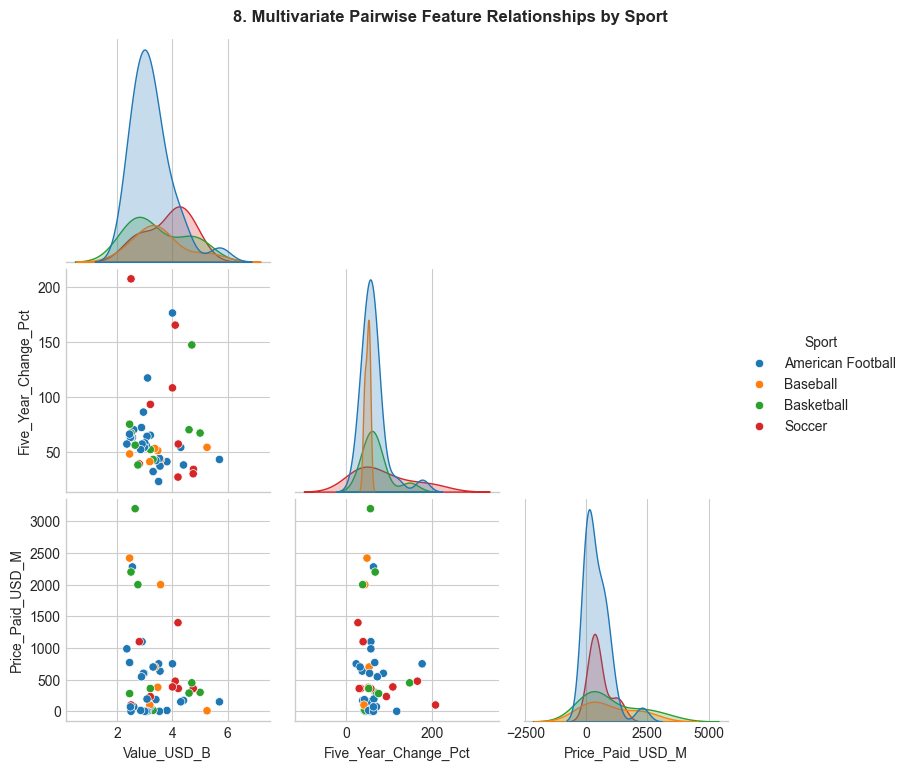

In [9]:
pair_df = df[['Value_USD_B', 'Five_Year_Change_Pct', 'Price_Paid_USD_M', 'Sport']]
g = sns.pairplot(pair_df, hue='Sport', corner=True, palette='tab10')
g.fig.suptitle("8. Multivariate Pairwise Feature Relationships by Sport", y=1.02, fontweight='bold')
plt.show()


### 9. Line Chart: Valuation by Purchase Decade
**Empirical Inference:**
> Franchises held since the 1920s-1970s maintain remarkably resilient multi-billion-dollar values. Meanwhile, franchises bought during the 2000s and 2010s show accelerated recent 5-year percentage valuation gains due to modernization and global streaming monetization.

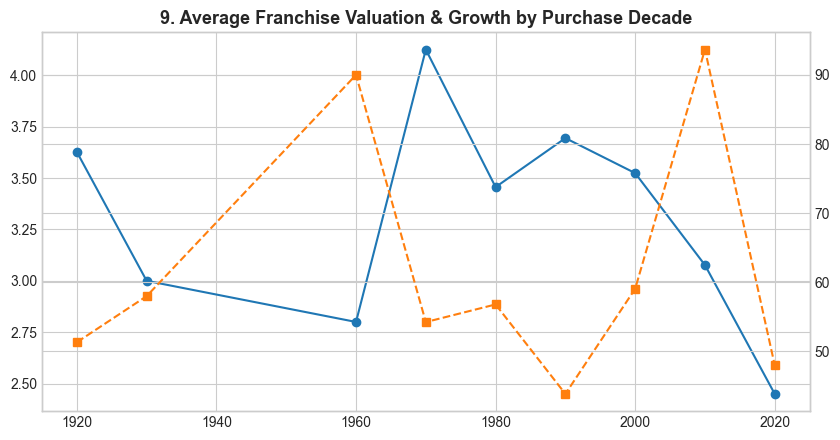

In [10]:
df_yr = df.sort_values(by='Year_Purchased_Clean').copy()
df_yr['Decade'] = (df_yr['Year_Purchased_Clean'] // 10) * 10
trend = df_yr.groupby('Decade').agg({'Value_USD_B': 'mean', 'Five_Year_Change_Pct': 'mean'}).reset_index()
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax2 = ax1.twinx()
ax1.plot(trend['Decade'], trend['Value_USD_B'], color='#1f77b4', marker='o', label='Mean Valuation ($B)')
ax2.plot(trend['Decade'], trend['Five_Year_Change_Pct'], color='#ff7f0e', marker='s', linestyle='--', label='Mean Growth (%)')
ax1.set_title("9. Average Franchise Valuation & Growth by Purchase Decade", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 10. Q-Q & Density: Normality Diagnostics
**Empirical Inference:**
> The Q-Q plot exhibits pronounced convex curvature at upper quantiles, confirming heavy positive skewness. This violates standard Gaussian assumptions, strongly justifying nonparametric and tree-based data mining methods (such as FP-Growth and Naive Bayes discretization).

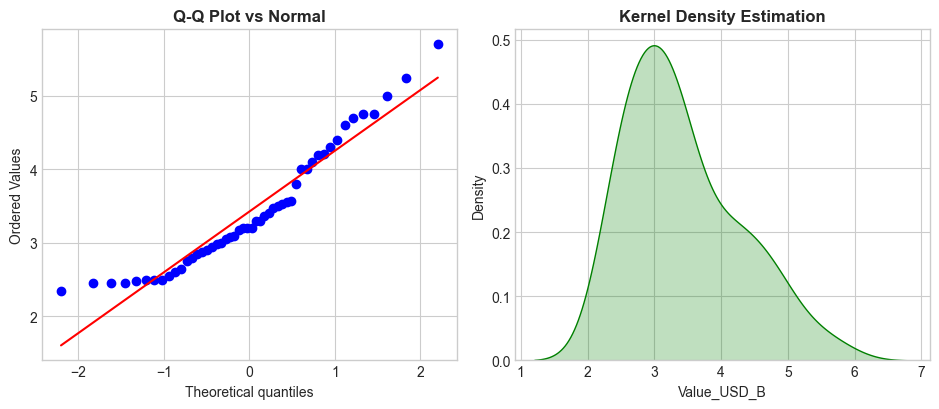

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.2))
stats.probplot(df['Value_USD_B'], dist="norm", plot=ax1)
sns.kdeplot(df['Value_USD_B'], fill=True, color='green', ax=ax2)
ax1.set_title("Q-Q Plot vs Normal", fontweight='bold')
ax2.set_title("Kernel Density Estimation", fontweight='bold')
plt.tight_layout()
plt.show()


### 11. Stacked Bar Chart: Geographic Distribution
**Empirical Inference:**
> American Football, Baseball, and Basketball are 100% geographically concentrated in the USA. Conversely, the Soccer category is partitioned across the UK (5 teams), Spain (2 teams), Germany (1 team), and France (1 team), illustrating Europe's polycentric soccer landscape.

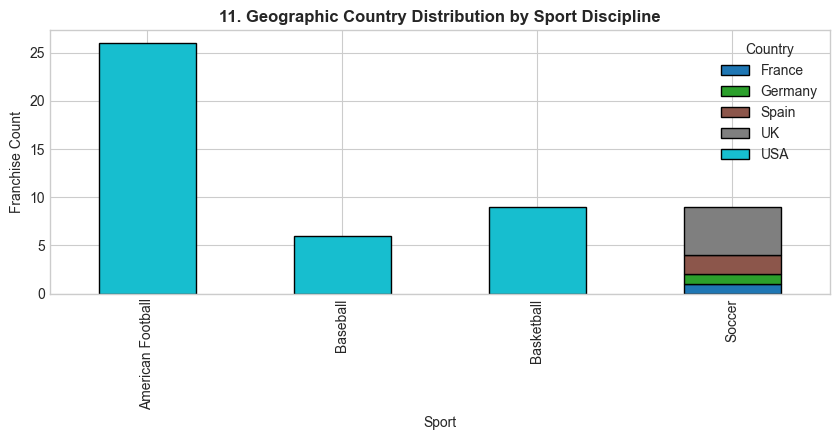

In [12]:
pd.crosstab(df['Sport'], df['Country']).plot(kind='bar', stacked=True, colormap='tab10', edgecolor='black', figsize=(8.5, 4.5))
plt.title("11. Geographic Country Distribution by Sport Discipline", fontweight='bold')
plt.ylabel("Franchise Count")
plt.tight_layout()
plt.show()


### 12. Bubble Chart: Valuation vs. Growth (Size = Tenure)
**Empirical Inference:**
> Franchises held for decades (largest bubbles) occupy the upper valuation plateau with steady compound gains. Outlying high-growth properties (e.g., Golden State Warriors, LA Rams, PSG) are medium-sized bubbles purchased in the modern era, capturing rapid franchise re-evaluations.

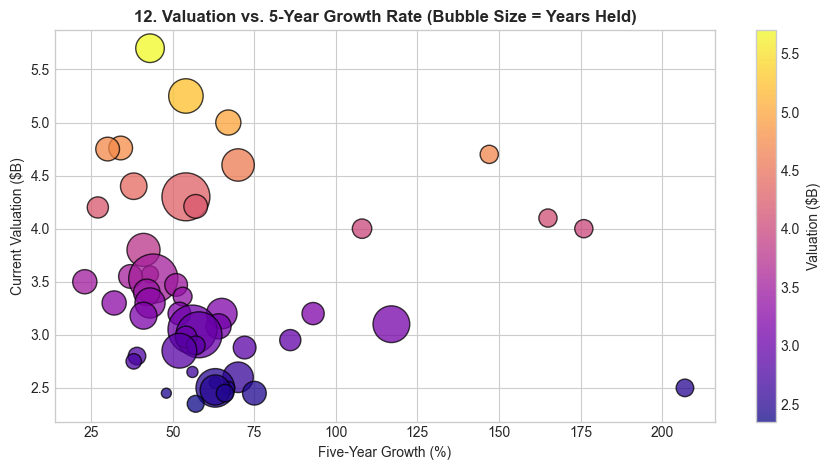

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8))
scatter = ax.scatter(df['Five_Year_Change_Pct'], df['Value_USD_B'], s=df['Years_Held']*12 + 40, c=df['Value_USD_B'], cmap='plasma', alpha=0.75, edgecolors='black')
plt.colorbar(scatter, ax=ax, label="Valuation ($B)")
ax.set_title("12. Valuation vs. 5-Year Growth Rate (Bubble Size = Years Held)", fontweight='bold')
ax.set_xlabel("Five-Year Growth (%)")
ax.set_ylabel("Current Valuation ($B)")
plt.tight_layout()
plt.show()
